In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier



In [ ]:

df = pd.read_csv("/content/features_30_sec_with_missing_values.csv")



In [ ]:
print(df.shape)

(1000, 60)


In [ ]:
df.head()

,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794.0,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794.0,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,NaN,blues
2,blues.00002.wav,661794.0,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794.0,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794.0,0.308526,0.087841,0.091529,0.002303,1835.004266,NaN,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,NaN,-11.703234,55.195160,blues


In [ ]:

print(df.columns)




Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  

In [ ]:
print(df.dtypes)




filename                    object
length                     float64
chroma_stft_mean           float64
chroma_stft_var            float64
rms_mean                   float64
rms_var                    float64
spectral_centroid_mean     float64
spectral_centroid_var      float64
spectral_bandwidth_mean    float64
spectral_bandwidth_var     float64
rolloff_mean               float64
rolloff_var                float64
zero_crossing_rate_mean    float64
zero_crossing_rate_var     float64
harmony_mean               float64
harmony_var                float64
perceptr_mean              float64
perceptr_var               float64
tempo                      float64
mfcc1_mean                 float64
mfcc1_var                  float64
mfcc2_mean                 float64
mfcc2_var                  float64
mfcc3_mean                 float64
mfcc3_var                  float64
mfcc4_mean                 float64
mfcc4_var                  float64
mfcc5_mean                 float64
mfcc5_var           

In [ ]:
df.info()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   object 
 1   length                   980 non-null    float64
 2   chroma_stft_mean         977 non-null    float64
 3   chroma_stft_var          972 non-null    float64
 4   rms_mean                 970 non-null    float64
 5   rms_var                  980 non-null    float64
 6   spectral_centroid_mean   967 non-null    float64
 7   spectral_centroid_var    966 non-null    float64
 8   spectral_bandwidth_mean  965 non-null    float64
 9   spectral_bandwidth_var   975 non-null    float64
 10  rolloff_mean             963 non-null    float64
 11  rolloff_var              962 non-null    float64
 12  zero_crossing_rate_mean  966 non-null    float64
 13  zero_crossing_rate_var   964 non-null    float64
 14  harmony_mean             

In [ ]:
print(df.describe())

              length  chroma_stft_mean  chroma_stft_var    rms_mean  \
count     980.000000        977.000000       972.000000  970.000000   
mean   662037.455102          0.378763         0.086373    0.129947   
std      1801.498507          0.081111         0.007731    0.065323   
min    660000.000000          0.171939         0.044555    0.005276   
25%    661504.000000          0.320170         0.082298    0.086471   
50%    661794.000000          0.383111         0.086667    0.120620   
75%    661794.000000          0.435331         0.091265    0.173705   
max    675808.000000          0.663685         0.108111    0.397973   

          rms_var  spectral_centroid_mean  spectral_centroid_var  \
count  980.000000              967.000000           9.660000e+02   
mean     0.003031             2200.182060           4.687639e+05   
std      0.003639              716.279965           4.014724e+05   
min      0.000004              715.399707           7.911251e+03   
25%      0.000937   

In [ ]:
# To check Missing values :

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
length                     20
chroma_stft_mean           23
chroma_stft_var            28
rms_mean                   30
rms_var                    20
spectral_centroid_mean     33
spectral_centroid_var      34
spectral_bandwidth_mean    35
spectral_bandwidth_var     25
rolloff_mean               37
rolloff_var                38
zero_crossing_rate_mean    34
zero_crossing_rate_var     36
harmony_mean               29
harmony_var                33
perceptr_mean              21
perceptr_var               36
tempo                      30
mfcc1_mean                 28
mfcc1_var                  32
mfcc2_mean                 26
mfcc2_var                  36
mfcc3_mean                 35
mfcc3_var                  36
mfcc4_mean                 27
mfcc4_var                  30
mfcc5_mean                 40
mfcc5_var                  35
mfcc6_mean                 20
mfcc6_var                  23
mfcc7_mean                 35
mfcc7_var                  28
mfcc8_mea

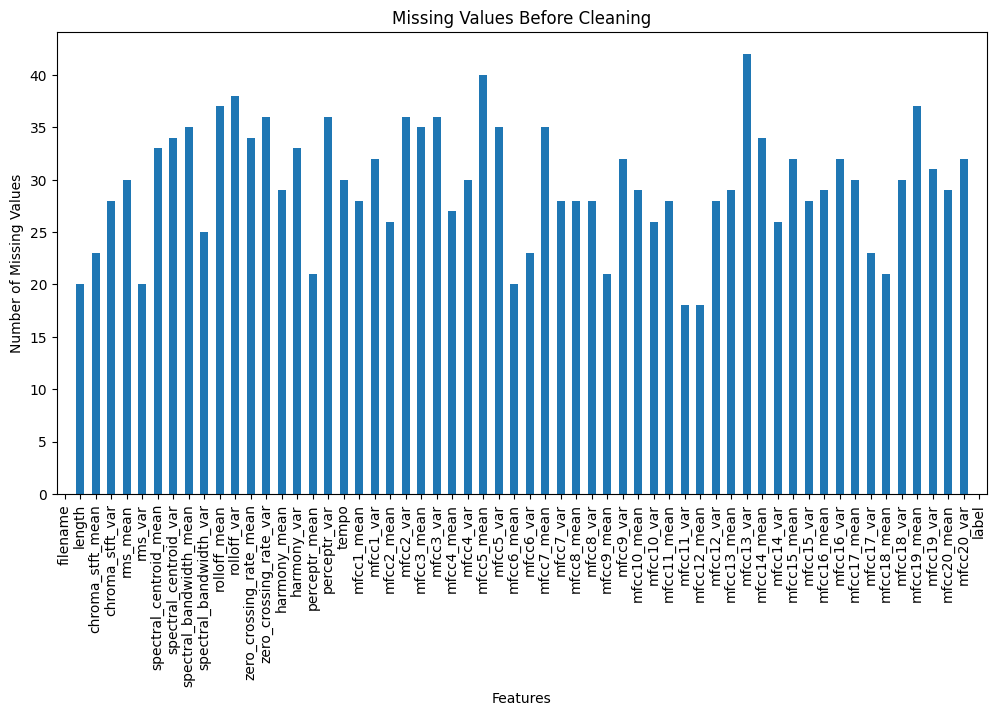

In [ ]:
plt.figure(figsize=(12, 6))

df.isnull().sum().plot(kind="bar")

plt.title("Missing Values Before Cleaning")
plt.xlabel("Features")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)

plt.show()

In [ ]:
# To remove duplicate records :

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print(df.shape)

Duplicate rows: 0
(1000, 60)


In [ ]:
# Handling Missing values :

# here in this we use median for numerical columns :

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

In [ ]:
# here in this code snippet we use mode for the data which contaibd categorical values :

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [ ]:
print("Total missing values after cleaning:")
print(df.isnull().sum().sum())

Total missing values after cleaning:
0


In [ ]:
# Detecting the features which containd outliers :
numeric_columns = df.select_dtypes(include=np.number).columns

outlier_report = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_count = len(outliers)

    outlier_report.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outlier_count
    ])

outlier_df = pd.DataFrame(
    outlier_report,
    columns=[
        "Feature",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count"
    ]
)

print(outlier_df)

                    Feature             Q1            Q3           IQR  \
0                    length  661504.000000  6.617940e+05  2.900000e+02   
1          chroma_stft_mean       0.321702  4.345066e-01  1.128050e-01   
2           chroma_stft_var       0.082502  9.118743e-02  8.685557e-03   
3                  rms_mean       0.087566  1.725986e-01  8.503245e-02   
4                   rms_var       0.000951  3.493663e-03  2.542601e-03   
5    spectral_centroid_mean    1644.834778  2.671808e+03  1.026973e+03   
6     spectral_centroid_var  187671.179194  5.934498e+05  4.057786e+05   
7   spectral_bandwidth_mean    1912.900497  2.566932e+03  6.540320e+02   
8    spectral_bandwidth_var   68588.187619  1.799245e+05  1.113363e+05   
9              rolloff_mean    3461.087695  5.507481e+03  2.046393e+03   
10              rolloff_var  803814.725598  2.478882e+06  1.675068e+06   
11  zero_crossing_rate_mean       0.071181  1.309689e-01  5.978764e-02   
12   zero_crossing_rate_var       0.00

In [ ]:
features_with_outliers = outlier_df[
    outlier_df["Outlier Count"] > 0
]

print("Features containing outliers:",features_with_outliers)


Features containing outliers:                     Feature             Q1            Q3           IQR  \
0                    length  661504.000000  6.617940e+05  2.900000e+02   
1          chroma_stft_mean       0.321702  4.345066e-01  1.128050e-01   
2           chroma_stft_var       0.082502  9.118743e-02  8.685557e-03   
3                  rms_mean       0.087566  1.725986e-01  8.503245e-02   
4                   rms_var       0.000951  3.493663e-03  2.542601e-03   
5    spectral_centroid_mean    1644.834778  2.671808e+03  1.026973e+03   
6     spectral_centroid_var  187671.179194  5.934498e+05  4.057786e+05   
7   spectral_bandwidth_mean    1912.900497  2.566932e+03  6.540320e+02   
8    spectral_bandwidth_var   68588.187619  1.799245e+05  1.113363e+05   
9              rolloff_mean    3461.087695  5.507481e+03  2.046393e+03   
10              rolloff_var  803814.725598  2.478882e+06  1.675068e+06   
11  zero_crossing_rate_mean       0.071181  1.309689e-01  5.978764e-02   
12   zer

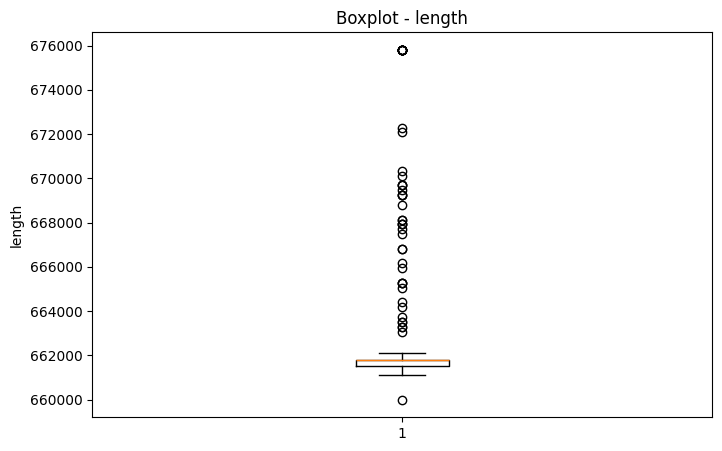

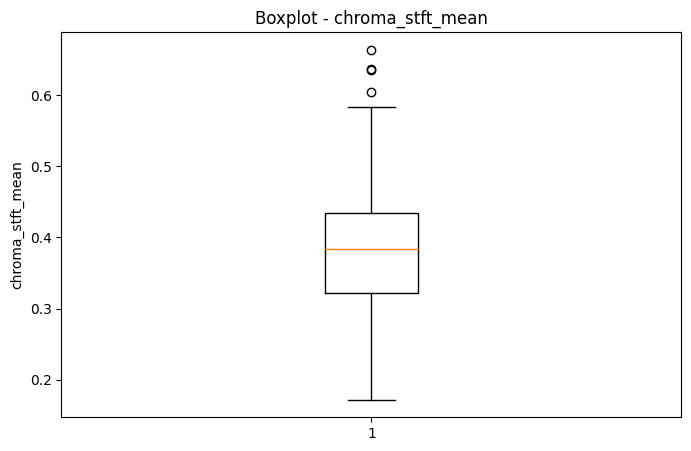

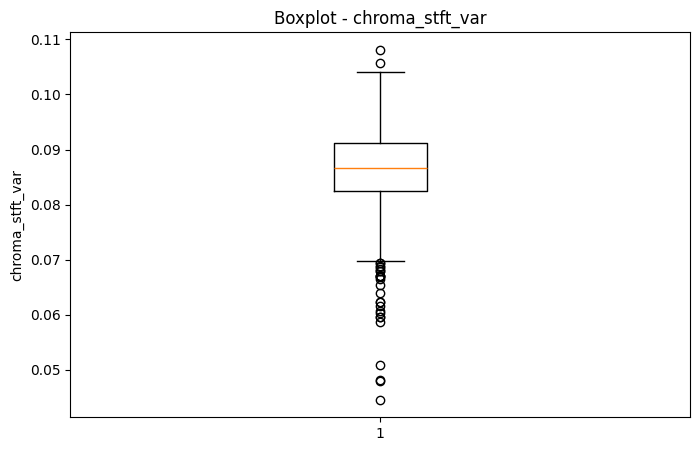

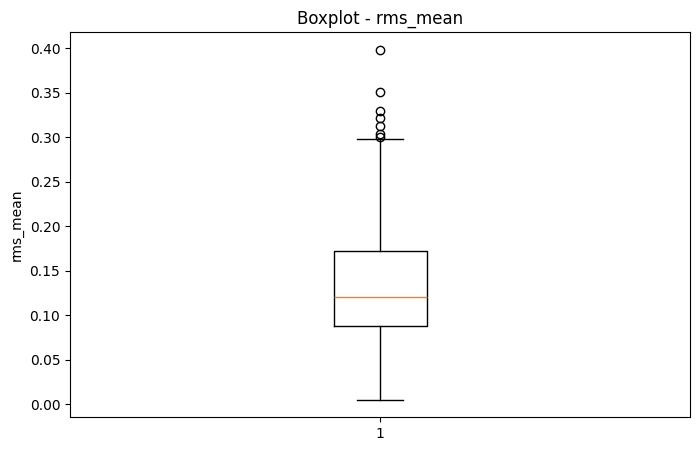

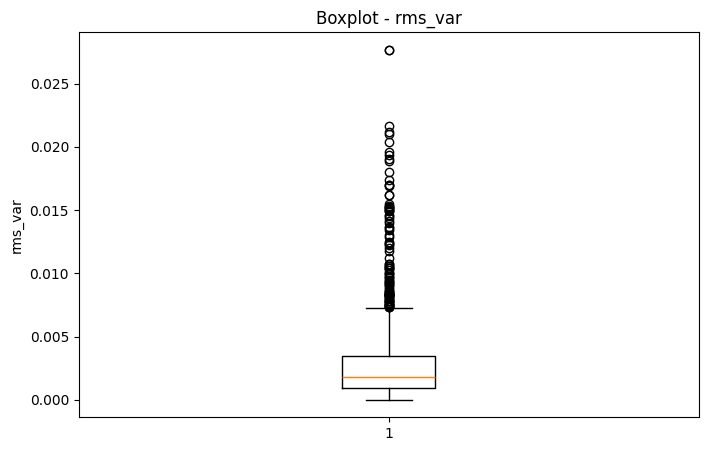

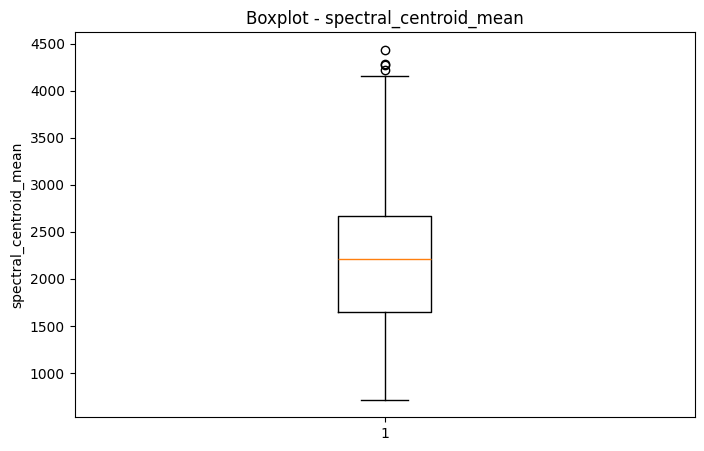

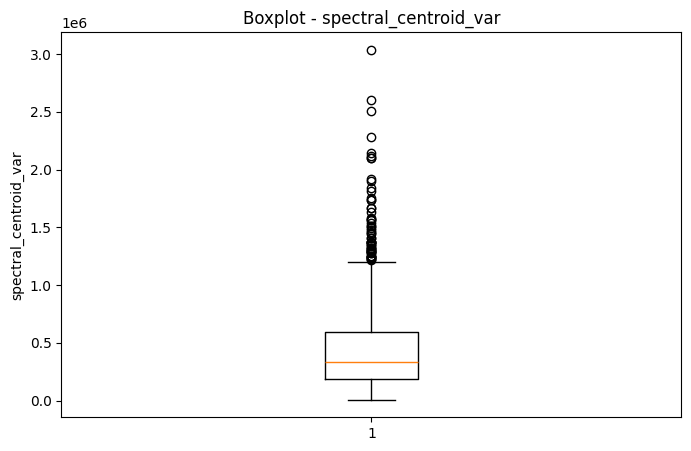

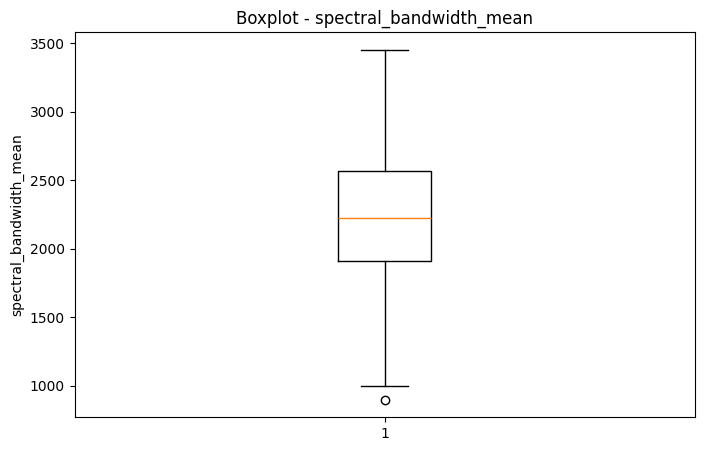

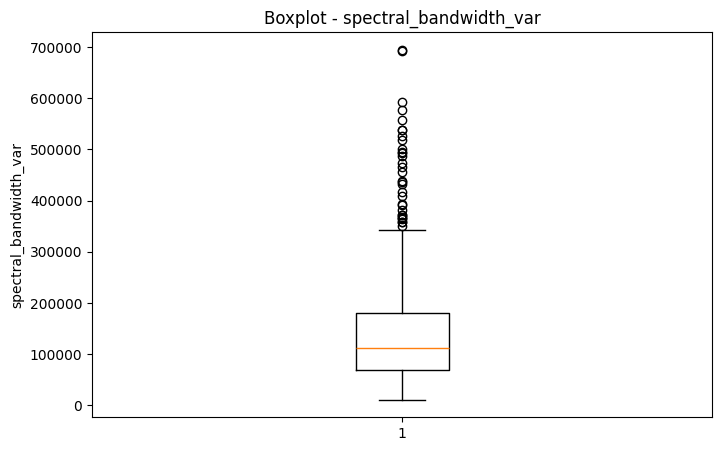

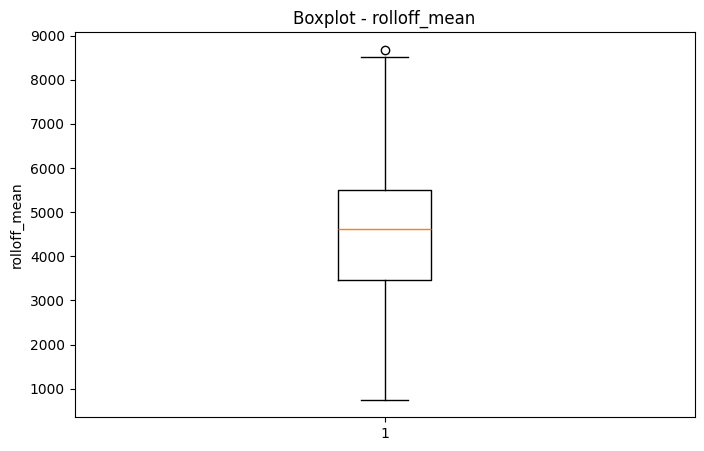

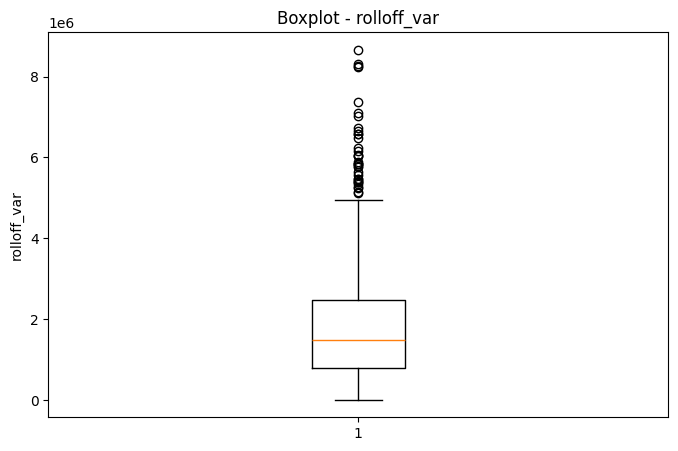

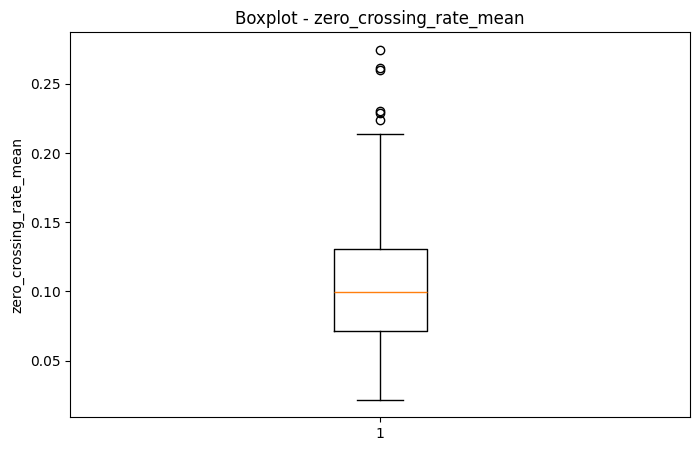

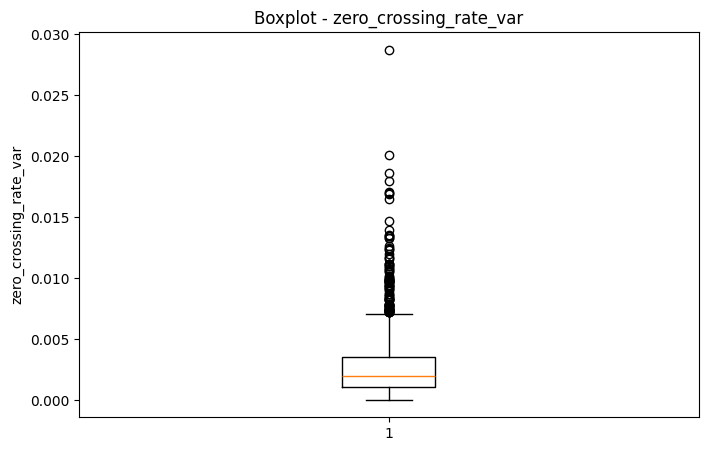

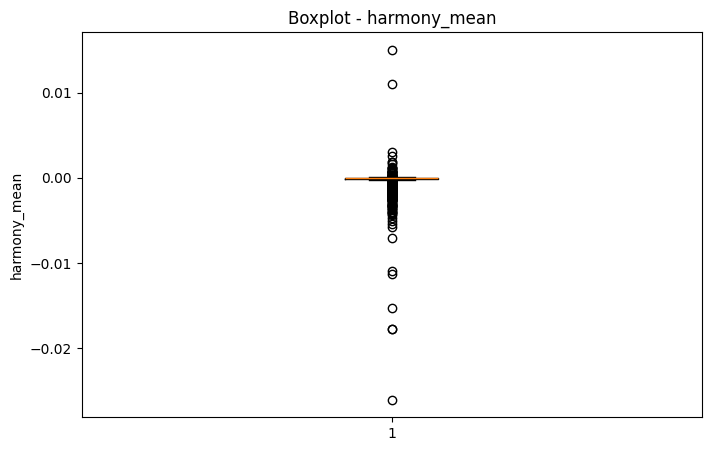

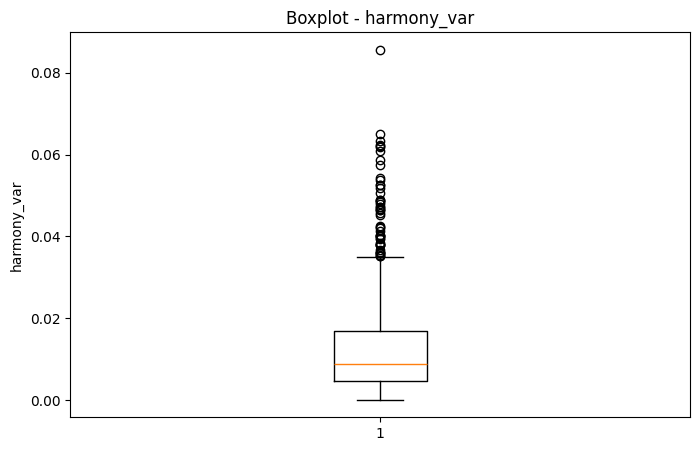

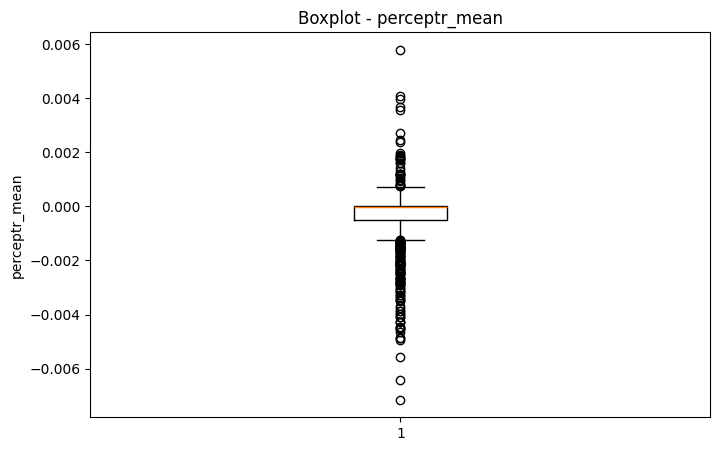

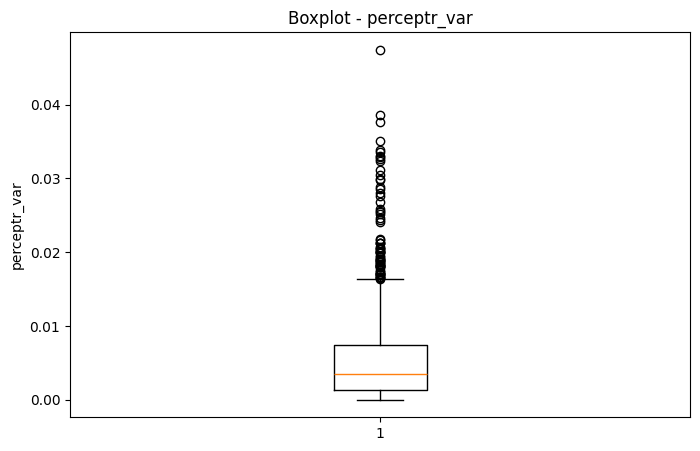

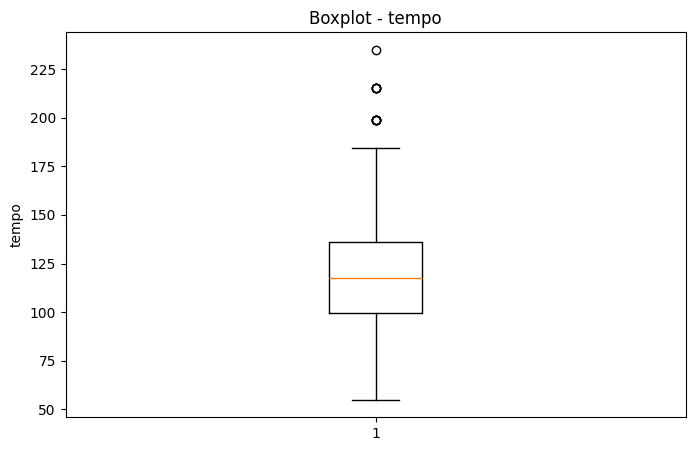

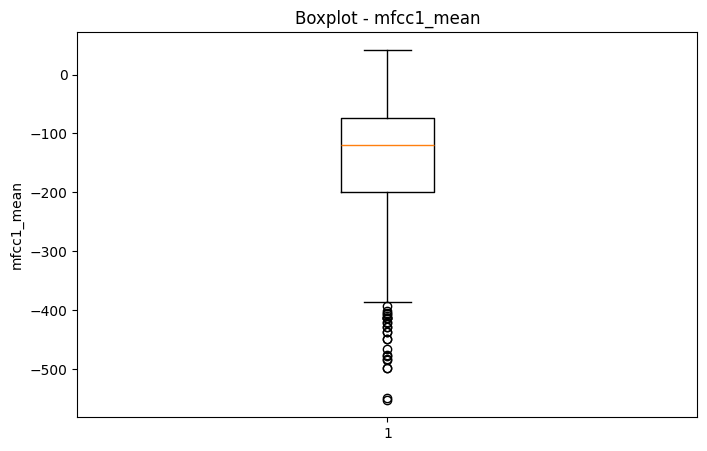

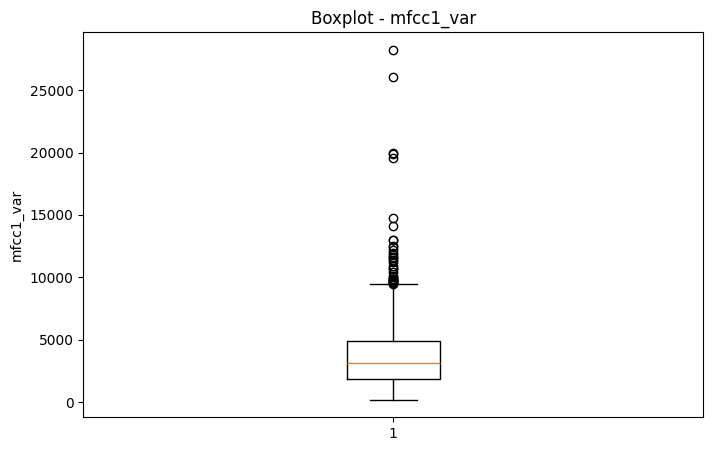

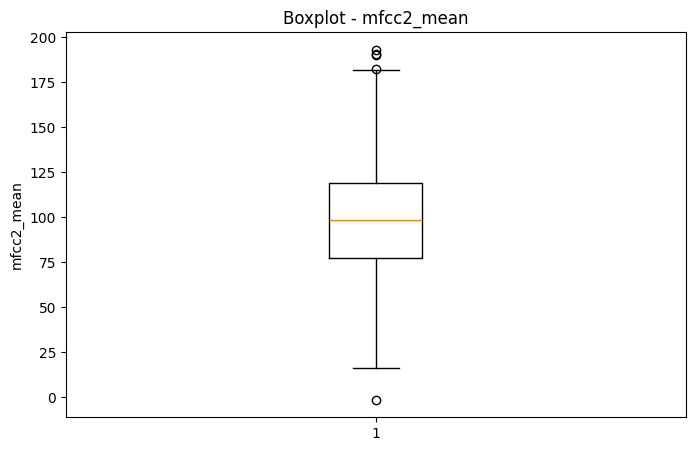

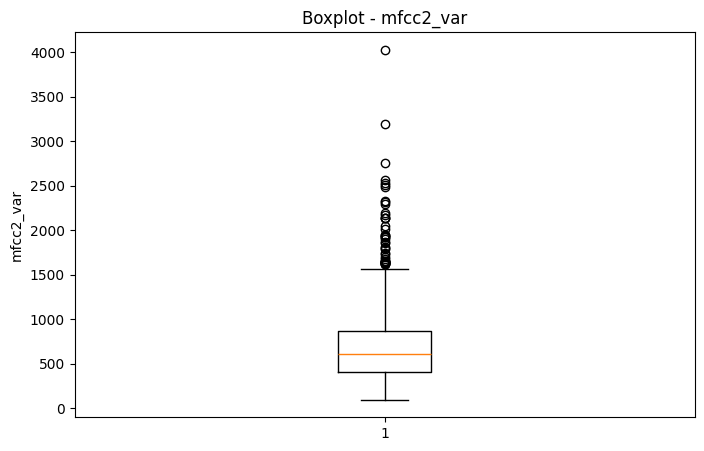

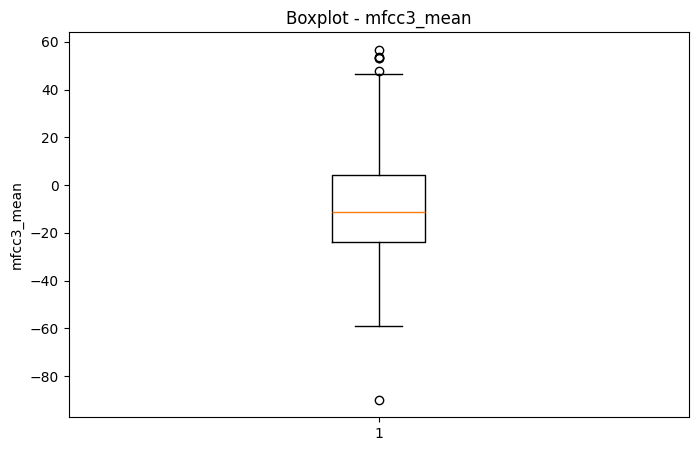

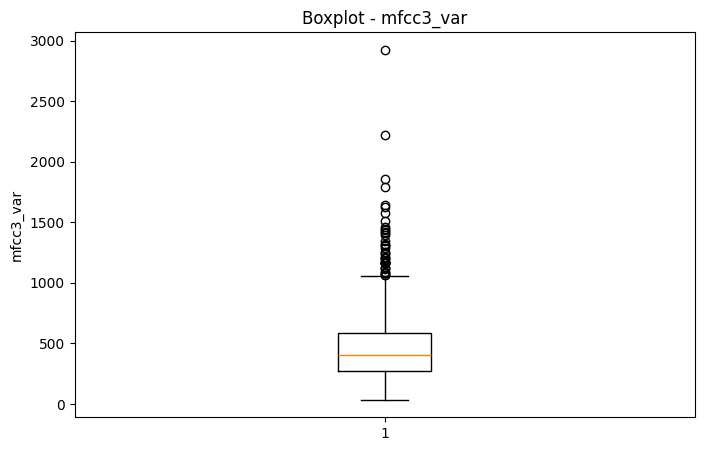

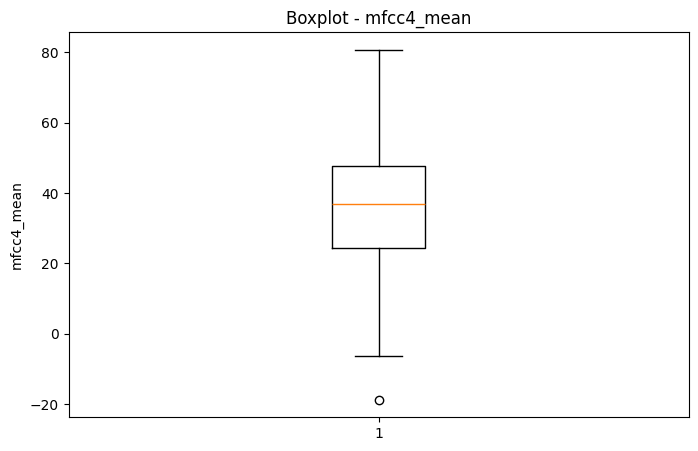

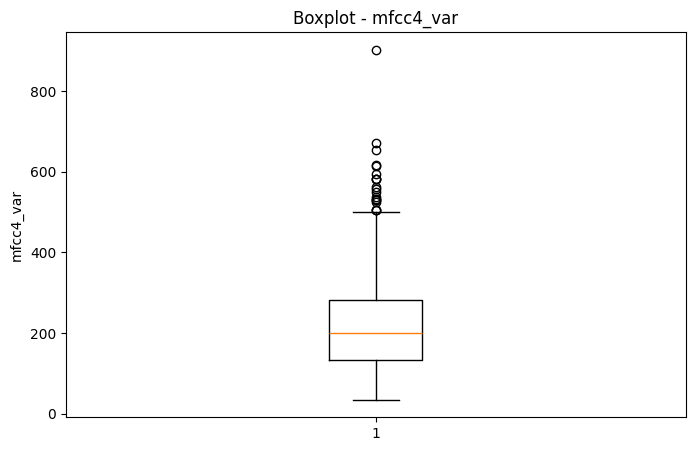

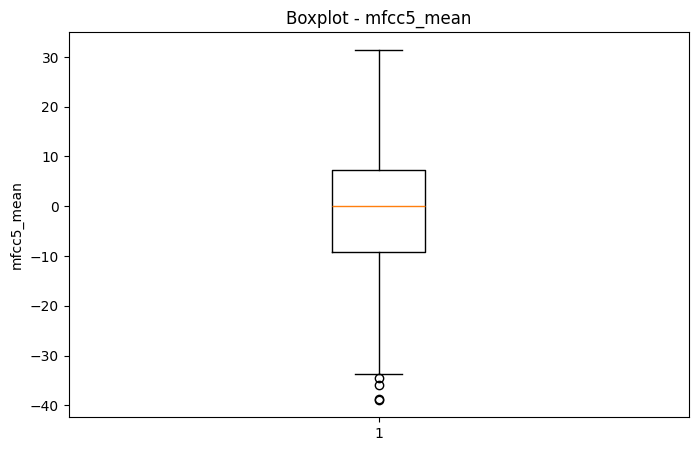

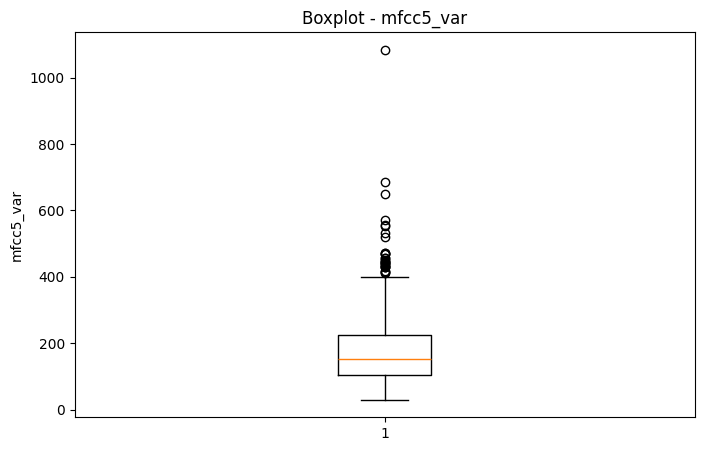

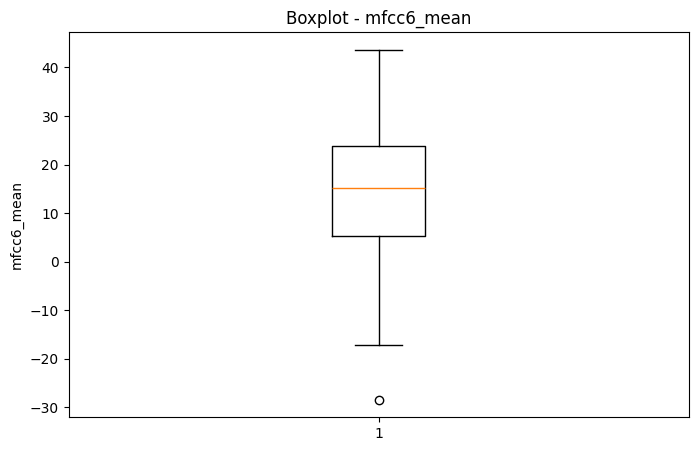

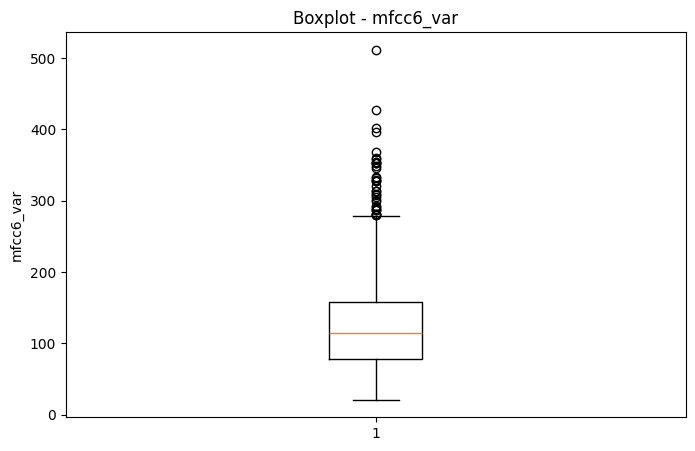

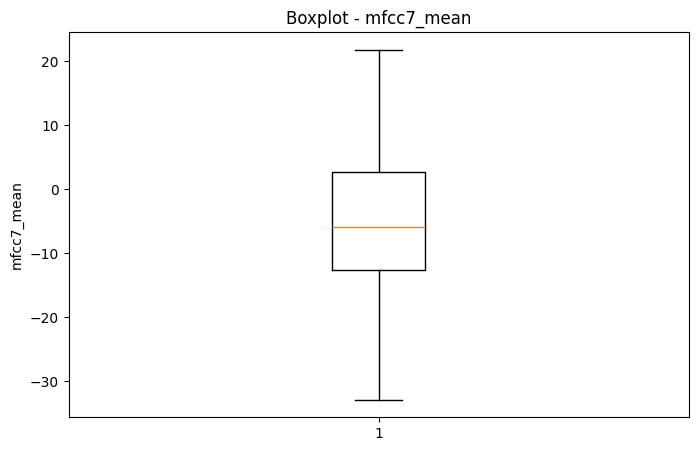

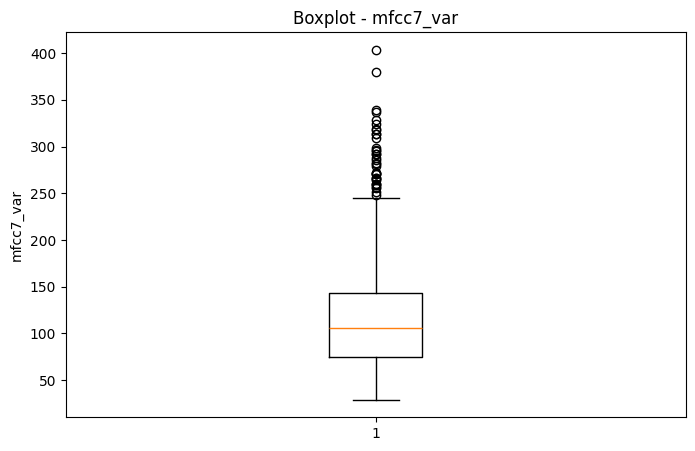

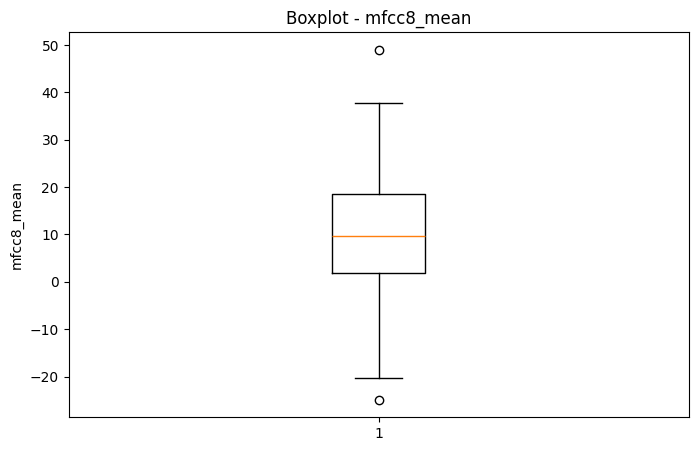

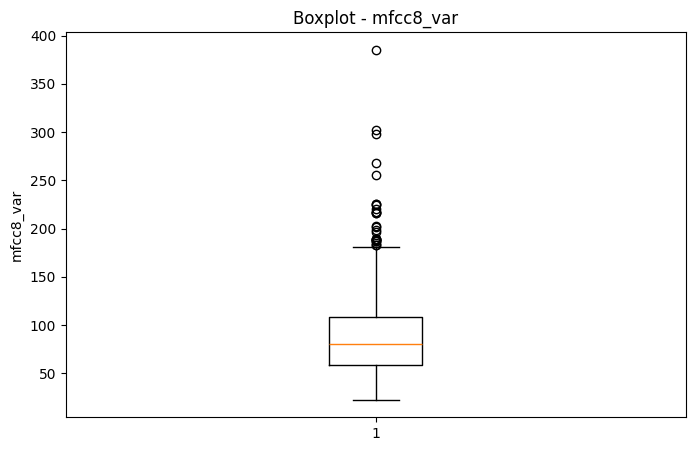

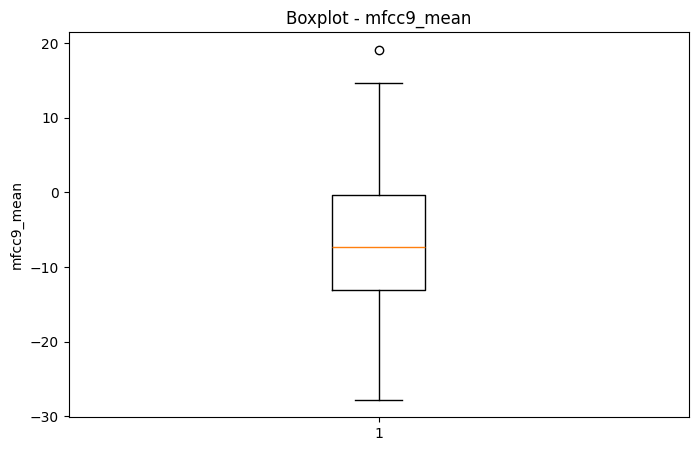

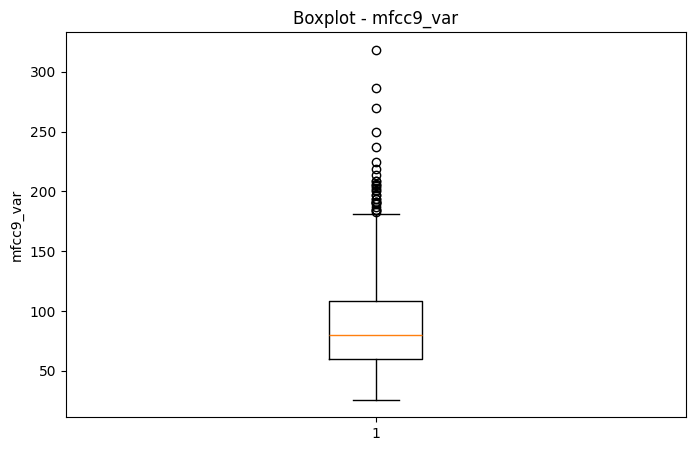

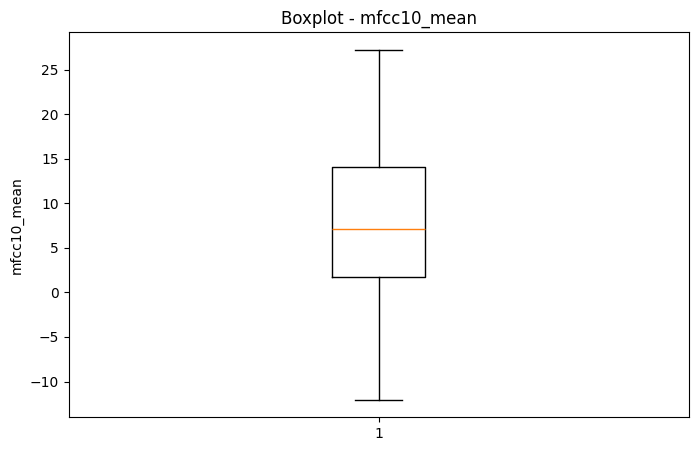

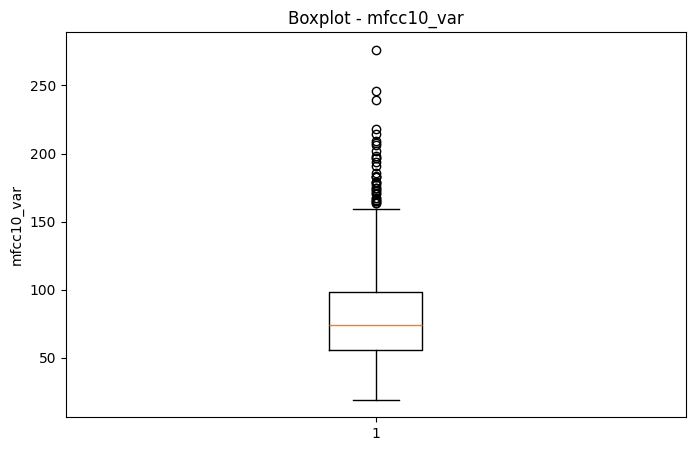

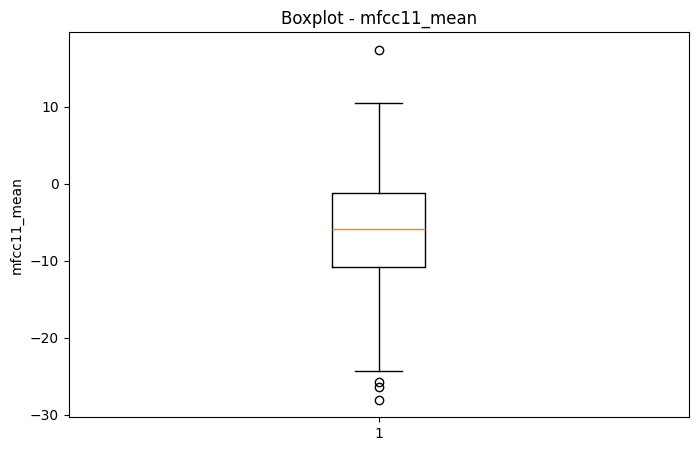

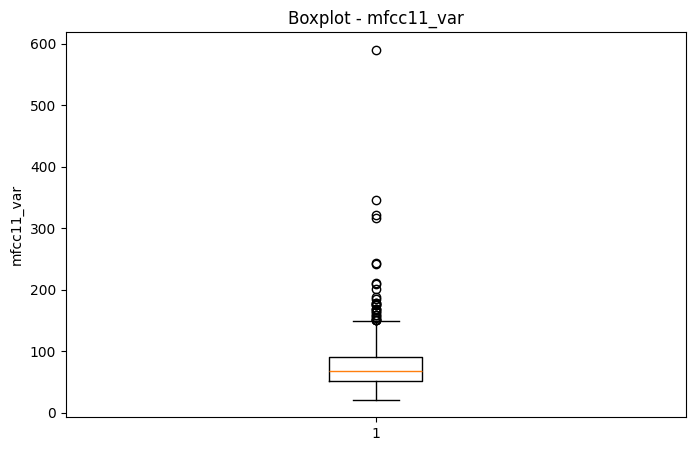

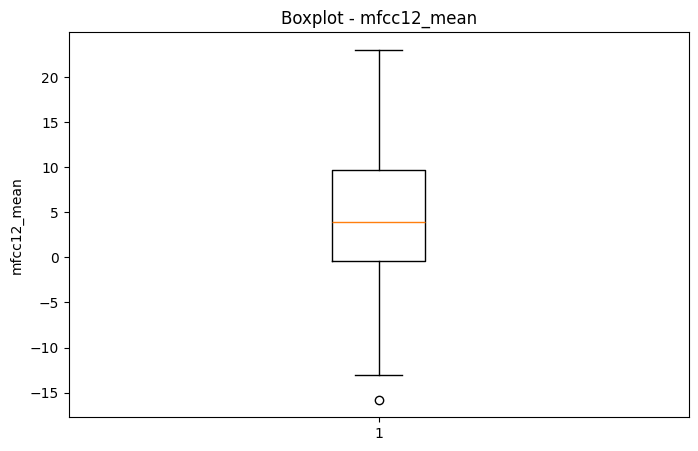

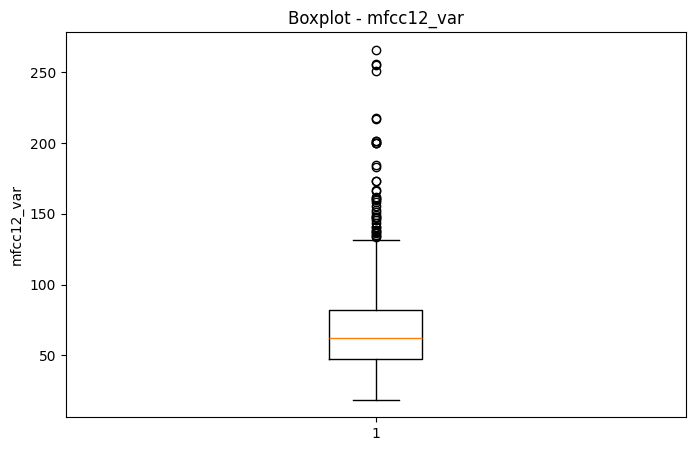

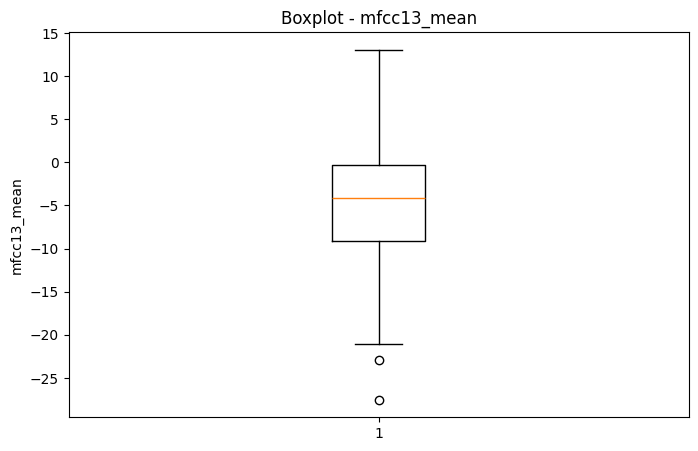

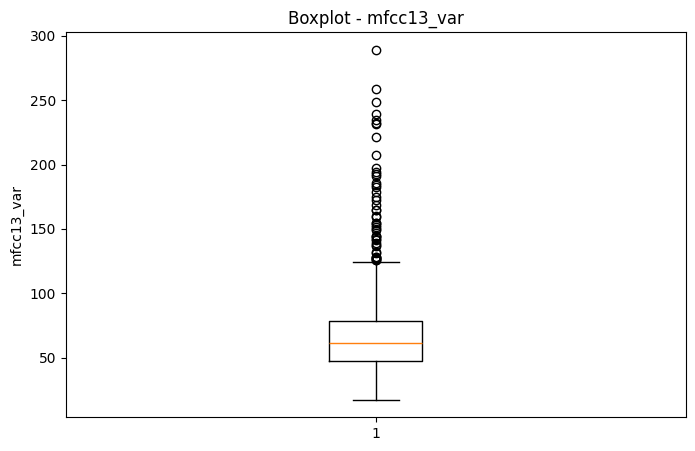

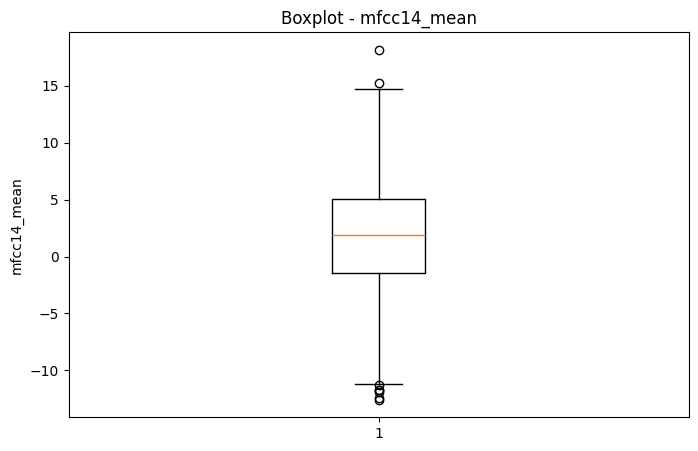

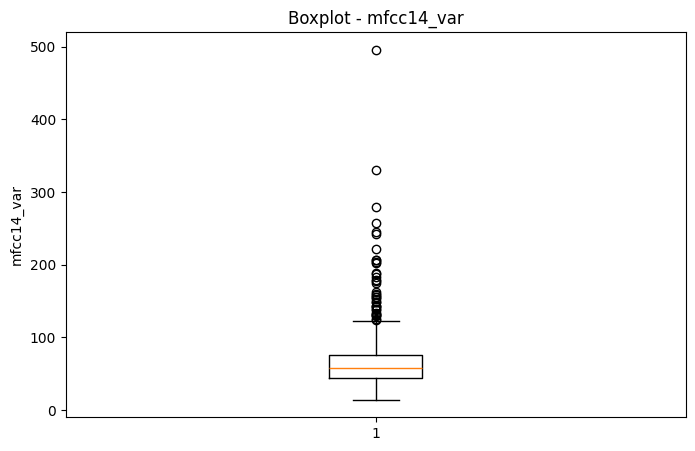

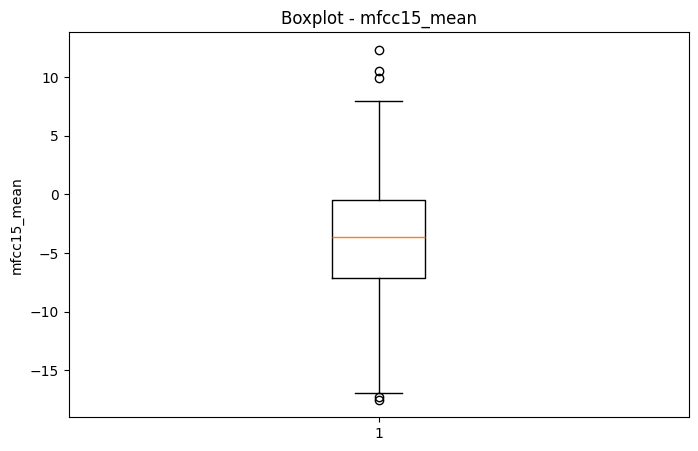

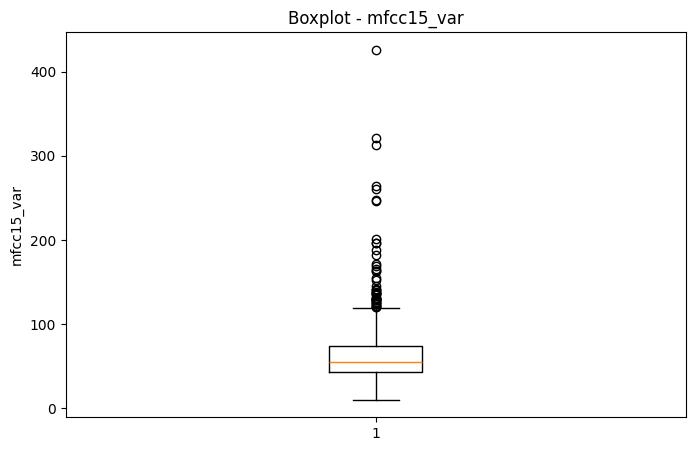

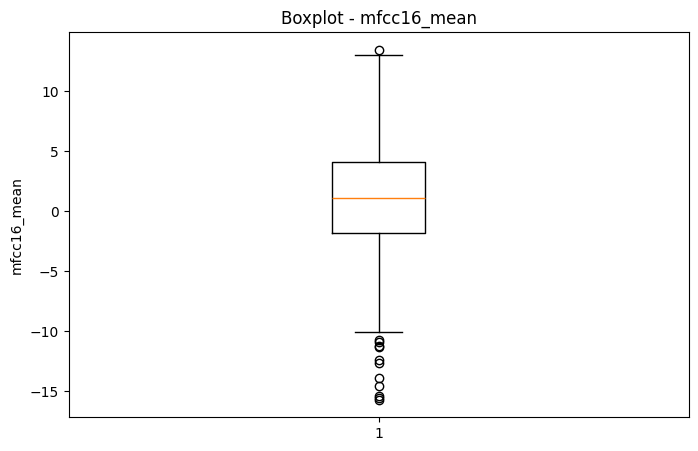

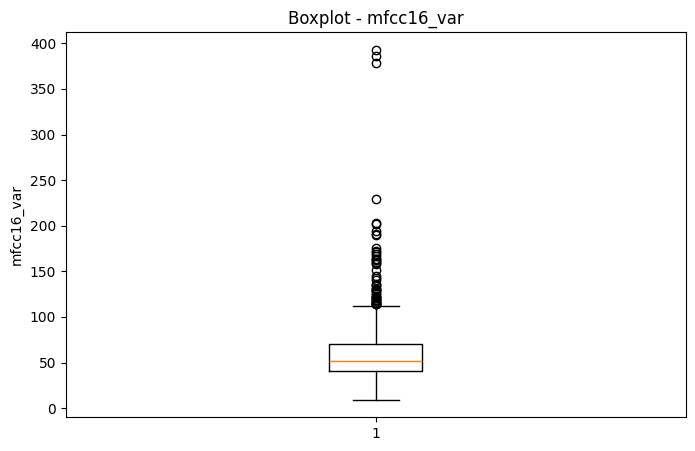

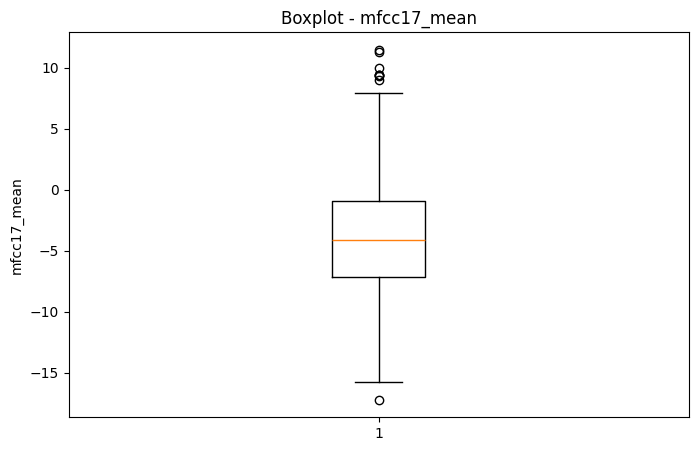

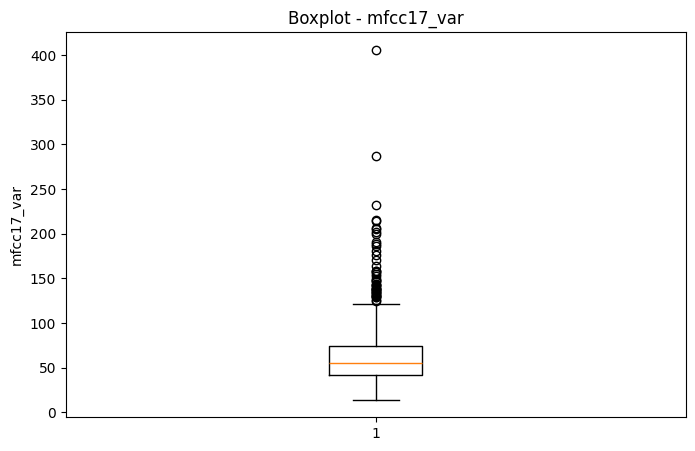

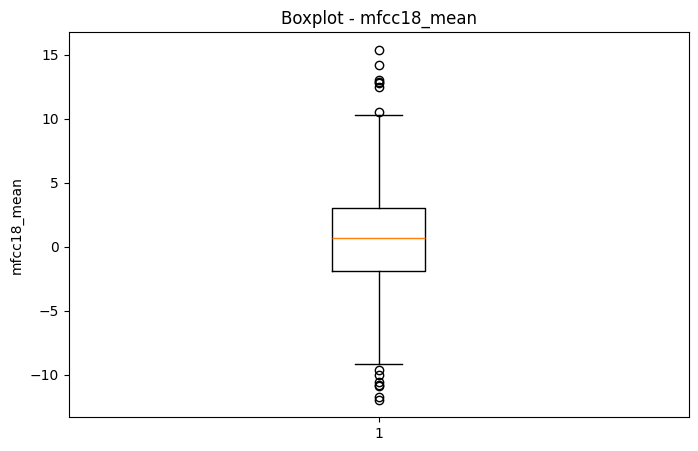

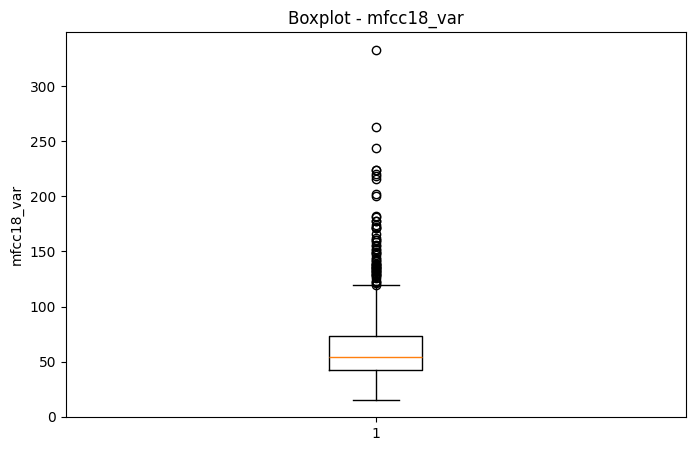

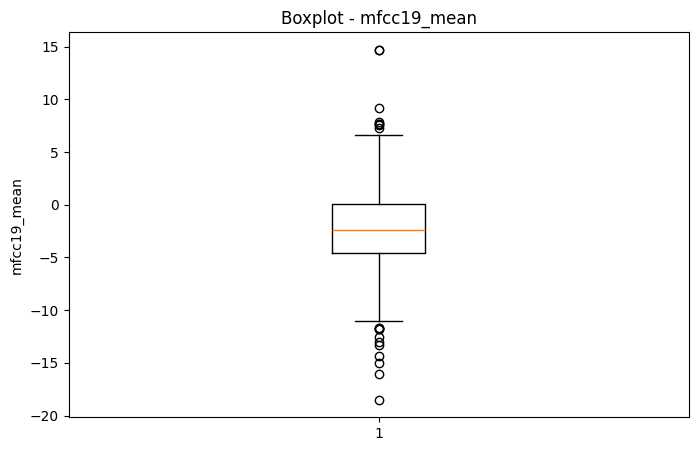

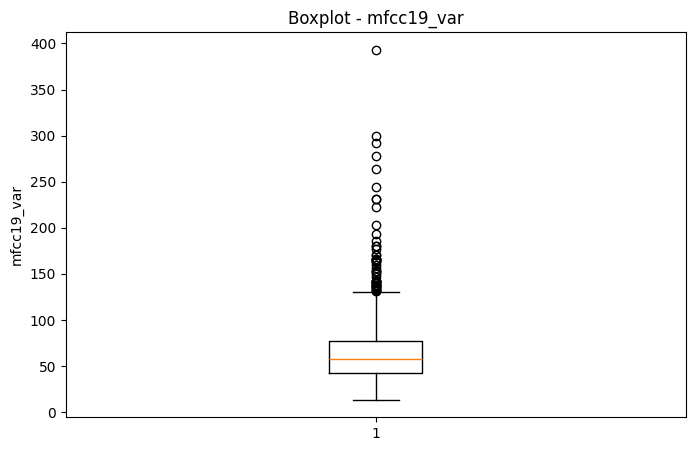

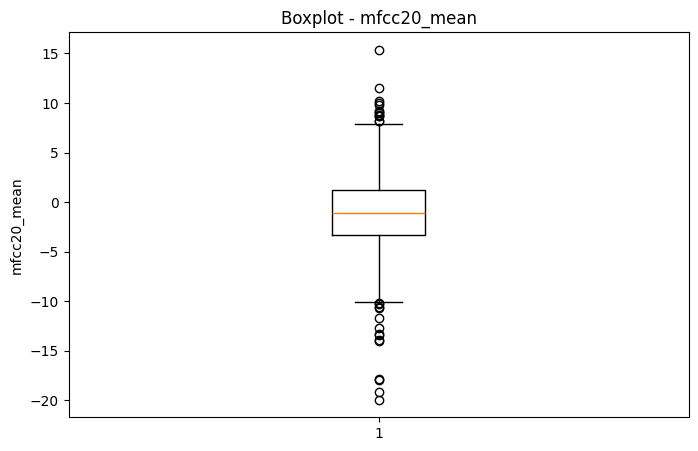

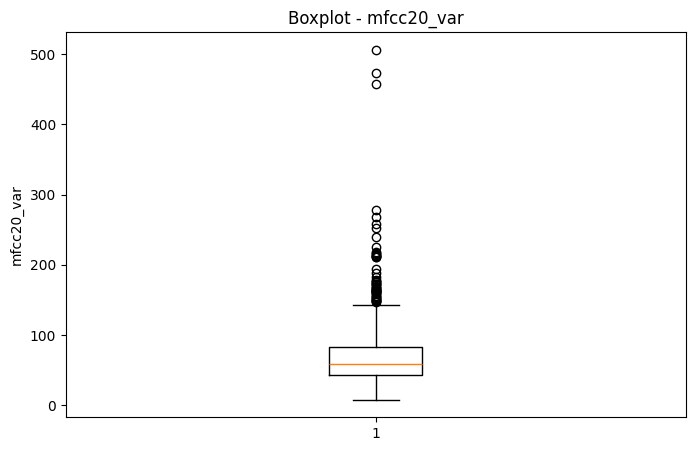

In [ ]:
# Boxplot for outlier detection:
for column in numeric_columns:

    plt.figure(figsize=(8, 5))

    plt.boxplot(df[column])

    plt.title("Boxplot - " + column)
    plt.ylabel(column)

    plt.show()

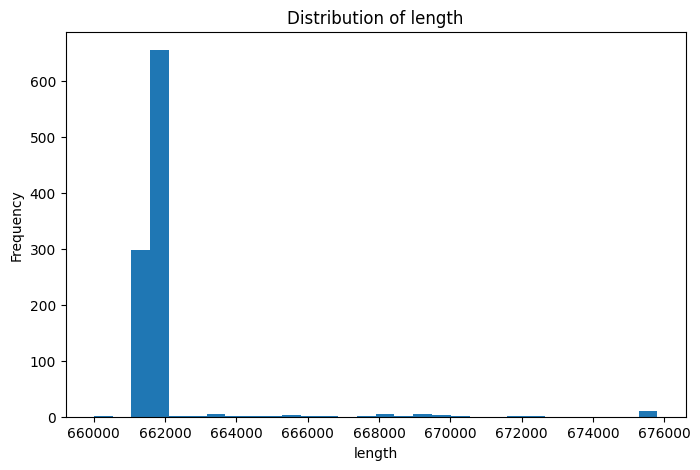

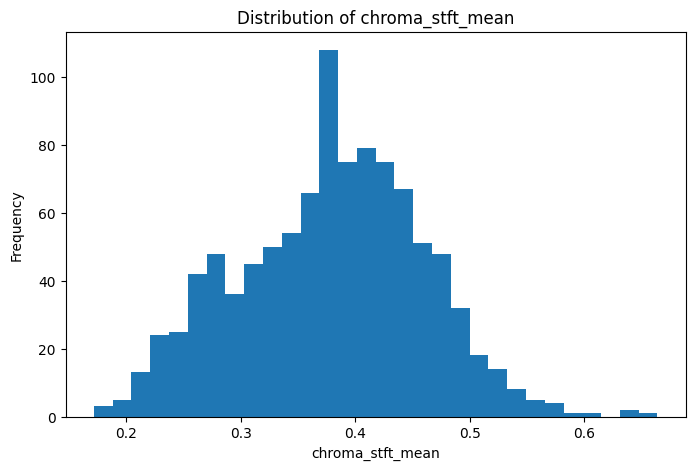

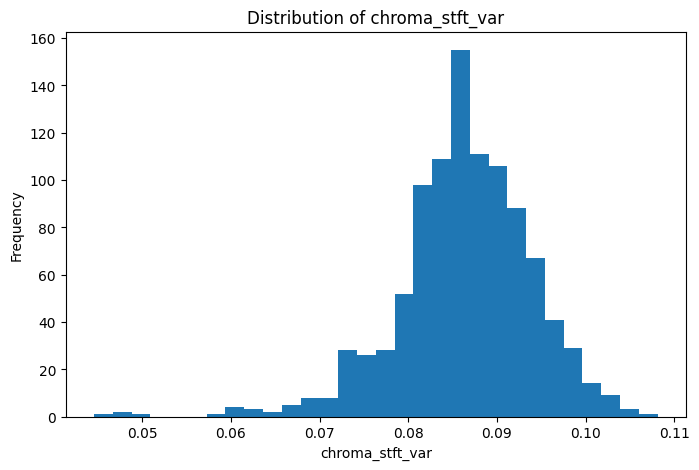

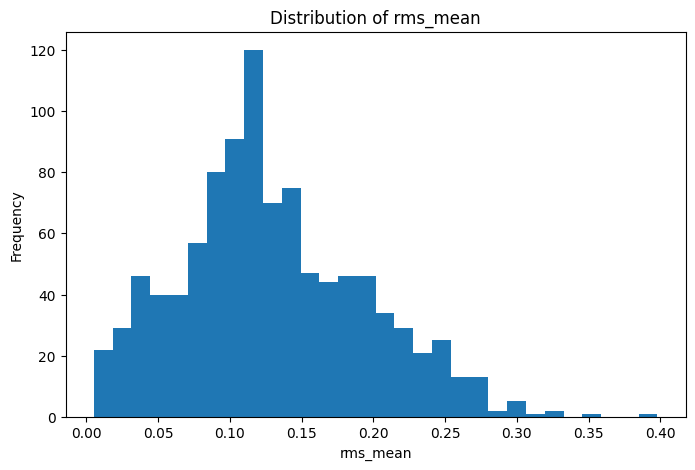

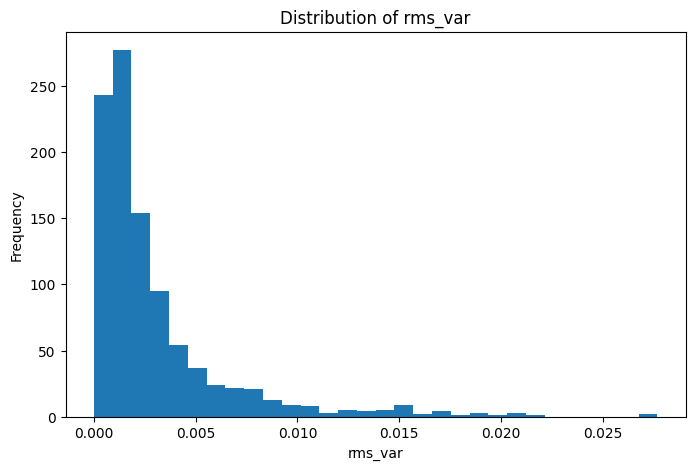

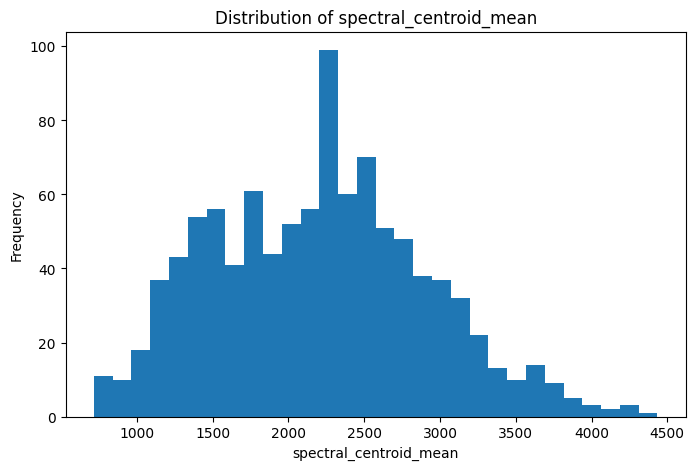

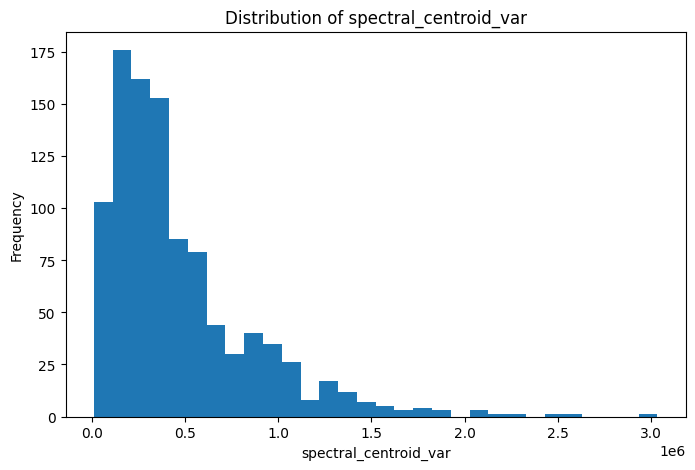

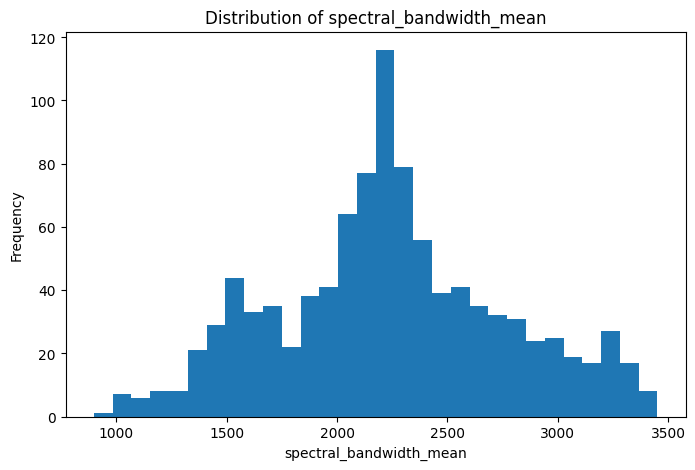

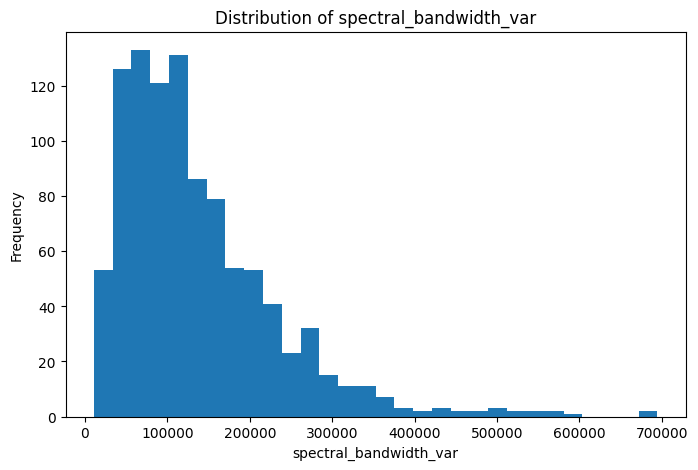

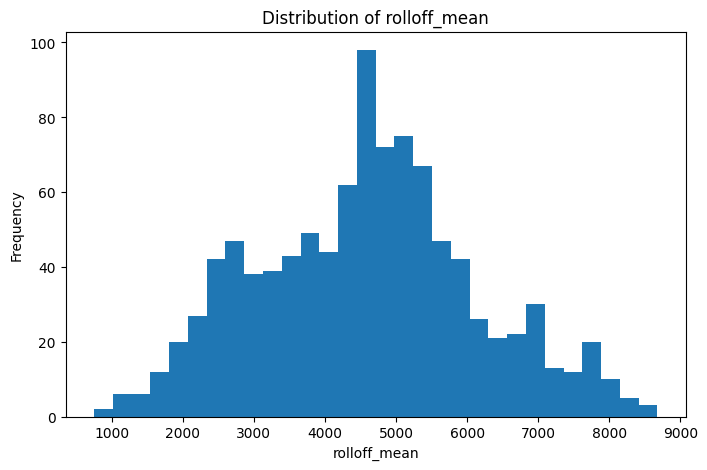

In [ ]:
# Histogram to visualize how our dataset fetures are distributed :

for column in numeric_columns[:10]:

    plt.figure(figsize=(8, 5))

    plt.hist(df[column], bins=30)

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

In [ ]:
# Genre Distribution through data visualization :

print(df.columns)


Index(['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean',
       'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var',
       'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean',
       'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var',
       'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo',
       'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean',
       'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var',
       'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean',
       'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var',
       'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean',
       'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var',
       'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean',
       'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var',
  

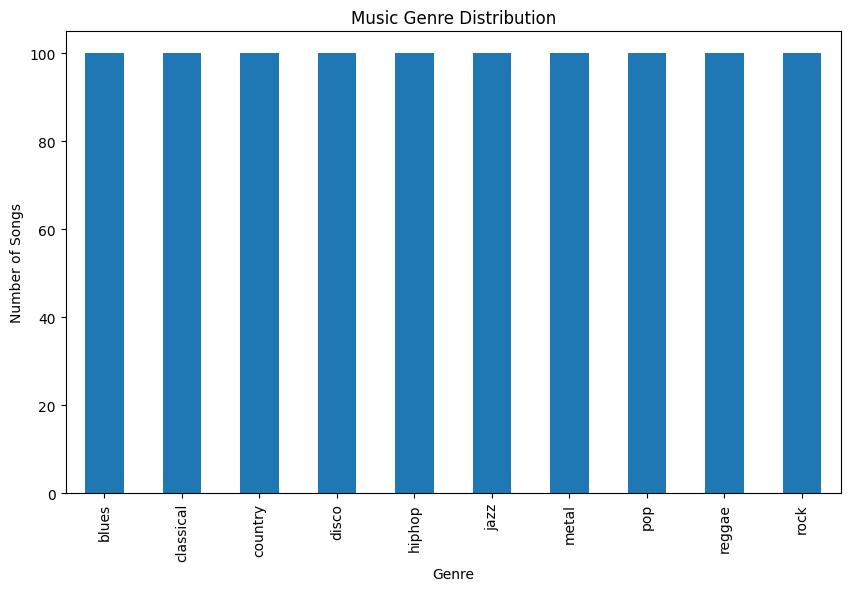

In [ ]:
plt.figure(figsize=(10, 6))

df["label"].value_counts().plot(kind="bar")

plt.title("Music Genre Distribution")
plt.xlabel("Genre")
plt.ylabel("Number of Songs")

plt.show()

In [ ]:
# Machine Learning Preprocessing :

X = df.drop("label", axis=1)

y = df["label"]

In [ ]:
print(X.dtypes)

filename                    object
length                     float64
chroma_stft_mean           float64
chroma_stft_var            float64
rms_mean                   float64
rms_var                    float64
spectral_centroid_mean     float64
spectral_centroid_var      float64
spectral_bandwidth_mean    float64
spectral_bandwidth_var     float64
rolloff_mean               float64
rolloff_var                float64
zero_crossing_rate_mean    float64
zero_crossing_rate_var     float64
harmony_mean               float64
harmony_var                float64
perceptr_mean              float64
perceptr_var               float64
tempo                      float64
mfcc1_mean                 float64
mfcc1_var                  float64
mfcc2_mean                 float64
mfcc2_var                  float64
mfcc3_mean                 float64
mfcc3_var                  float64
mfcc4_mean                 float64
mfcc4_var                  float64
mfcc5_mean                 float64
mfcc5_var           

In [ ]:
if "filename" in X.columns:
    X = X.drop("filename", axis=1)

In [ ]:
# To convert music genres into numbers  :



 # by label encoing :

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("Genre classes:")
print(encoder.classes_)

Genre classes:
[0 1 2 3 4 5 6 7 8 9]


In [ ]:
# Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 58)
Testing data: (200, 58)
